In [150]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("BlinkIT Grocery Data.xlsx")
print(df)

     Item Fat Content Item Identifier              Item Type  \
0             Regular           FDX32  Fruits and Vegetables   
1             Low Fat           NCB42     Health and Hygiene   
2             Regular           FDR28           Frozen Foods   
3             Regular           FDL50                 Canned   
4             Low Fat           DRI25            Soft Drinks   
...               ...             ...                    ...   
8518          low fat           NCT53     Health and Hygiene   
8519          low fat           FDN09            Snack Foods   
8520          low fat           DRE13            Soft Drinks   
8521              reg           FDT50                  Dairy   
8522              reg           FDM58            Snack Foods   

      Outlet Establishment Year Outlet Identifier Outlet Location Type  \
0                          2012            OUT049               Tier 1   
1                          2022            OUT018               Tier 3   
2        

First 5 Rows:

In [151]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


Last 5 Rows:

In [152]:
df.tail()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
8518,low fat,NCT53,Health and Hygiene,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,164.5526,4.0
8519,low fat,FDN09,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.034706,NaN,241.6828,4.0
8520,low fat,DRE13,Soft Drinks,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.027571,NaN,86.6198,4.0
8521,reg,FDT50,Dairy,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.107715,NaN,97.8752,4.0
8522,reg,FDM58,Snack Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.000000,NaN,112.2544,4.0


Information About Dataset:

In [153]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


Shape of the Dataset:

In [154]:
df.shape

(8523, 12)

Columns:

In [155]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

Statistical Summary:

In [156]:
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2016.450546,0.066132,12.857645,140.992783,3.965857
std,3.189396,0.051598,4.643456,62.275067,0.605651
min,2011.000000,0.000000,4.555000,31.290000,1.000000
25%,2014.000000,0.026989,8.773750,93.826500,4.000000
50%,2016.000000,0.053931,12.600000,143.012800,4.000000
75%,2018.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


Missing Values:

In [157]:
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64

Duplicate Records:

In [158]:
df.duplicated().sum()

np.int64(0)

In [159]:
df["Item Fat Content"].value_counts()

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Remove Duplicate Values:

In [160]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

Unique Values in Every Column:

In [161]:
df.nunique()

Item Fat Content                5
Item Identifier              1559
Item Type                      16
Outlet Establishment Year       9
Outlet Identifier              10
Outlet Location Type            3
Outlet Size                     3
Outlet Type                     4
Item Visibility              7880
Item Weight                   415
Sales                        5938
Rating                         39
dtype: int64

Questions==>

1.What is the total sales generated by Blinkit?

In [162]:
total_sales = df["Sales"].sum()
print(total_sales)

1201681.4928000001


2.Which Item Type Generate highest sales ? top 10

In [163]:
item_sales = df.groupby("Item Type")["Sales"].sum()
item_sales = item_sales.sort_values(ascending=False)
item_sales = item_sales.head(10)
print(item_sales)

Item Type
Fruits and Vegetables    178124.0810
Snack Foods              175433.9224
Household                135976.5254
Frozen Foods             118558.8814
Dairy                    101276.4616
Canned                    90706.7290
Baking Goods              81894.7364
Health and Hygiene        68025.8388
Meat                      59449.8638
Soft Drinks               58514.1670
Name: Sales, dtype: float64


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_5464\3754037711.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


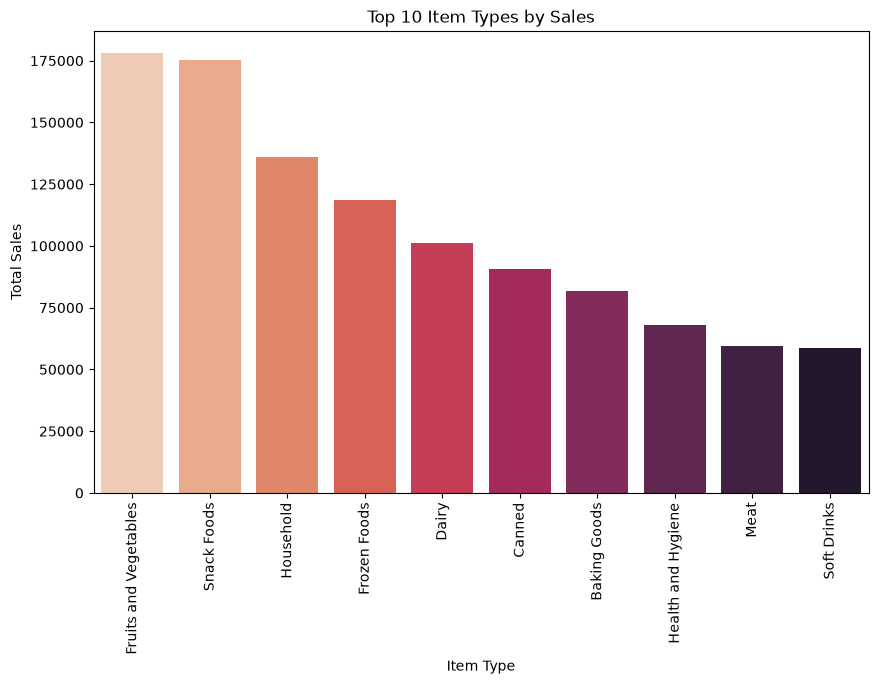

In [164]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=item_sales.index,
    y=item_sales.values,
    palette="rocket_r"
)
plt.xticks(rotation=90)
plt.title("Top 10 Item Types by Sales")
plt.xlabel("Item Type")
plt.ylabel("Total Sales")
plt.show()
plt.close()

3.Which Outlet Type has the highest total sales?

In [165]:
outlet_sales = df.groupby("Outlet Type")["Sales"].sum()
outlet_sales = outlet_sales.sort_values(ascending=False)
print(outlet_sales)

Outlet Type
Supermarket Type1    787549.8928
Grocery Store        151939.1490
Supermarket Type2    131477.7764
Supermarket Type3    130714.6746
Name: Sales, dtype: float64


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_5464\3348850478.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


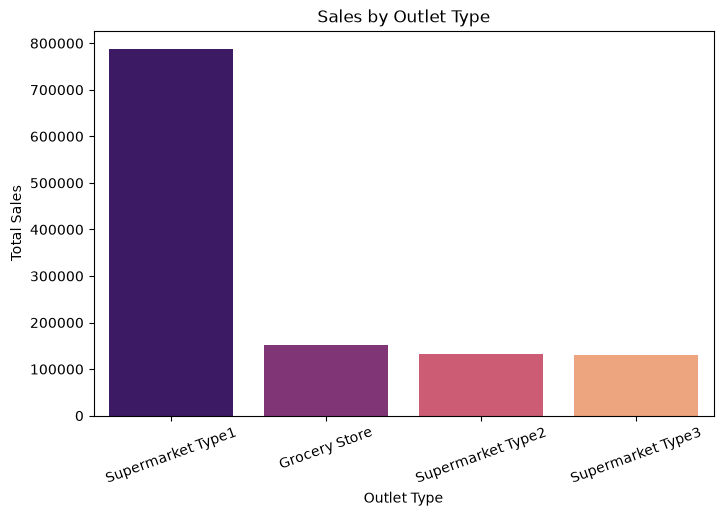

In [166]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=outlet_sales.index,
    y=outlet_sales.values,
    palette="magma"
)
plt.xticks(rotation=20)
plt.title("Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")
plt.show()
plt.close()

4.What is the sales distribution by Outlet Location Type?

In [167]:
location_sales = df.groupby("Outlet Location Type")["Sales"].sum()
location_sales = location_sales.sort_values(ascending=False)
print(location_sales)

Outlet Location Type
Tier 3    472133.0332
Tier 2    393150.6476
Tier 1    336397.8120
Name: Sales, dtype: float64


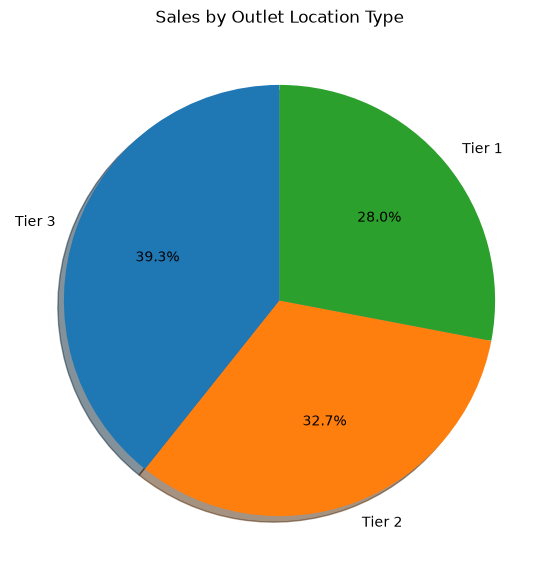

In [168]:
plt.figure(figsize=(7,7))
plt.pie(
    location_sales.values,
    labels=location_sales.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=True
)
plt.title("Sales by Outlet Location Type")
plt.show()
plt.close()

5.Which Outlet Size contributes the most to sales?

In [169]:
outlet_size = df.groupby("Outlet Size")["Sales"].sum()
outlet_size = outlet_size.sort_values(ascending=False)
print(outlet_size)

Outlet Size
Medium    507895.7364
Small     444794.1704
High      248991.5860
Name: Sales, dtype: float64


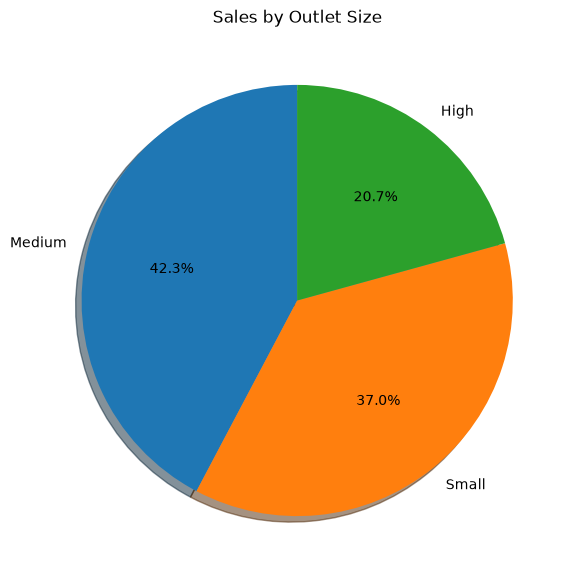

In [170]:
plt.figure(figsize=(7,7))
plt.pie(
    outlet_size.values,
    labels=outlet_size.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=True
)
plt.title("Sales by Outlet Size")
plt.show()
plt.close()

6.How has Blinkit expanded over the years?

In [171]:
outlet_year = df.groupby("Outlet Establishment Year")["Outlet Identifier"].count()
outlet_year = outlet_year.sort_index()
print(outlet_year)

Outlet Establishment Year
2011     555
2012     930
2014     932
2015     929
2016     930
2017     930
2018    1463
2020     926
2022     928
Name: Outlet Identifier, dtype: int64


In [172]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

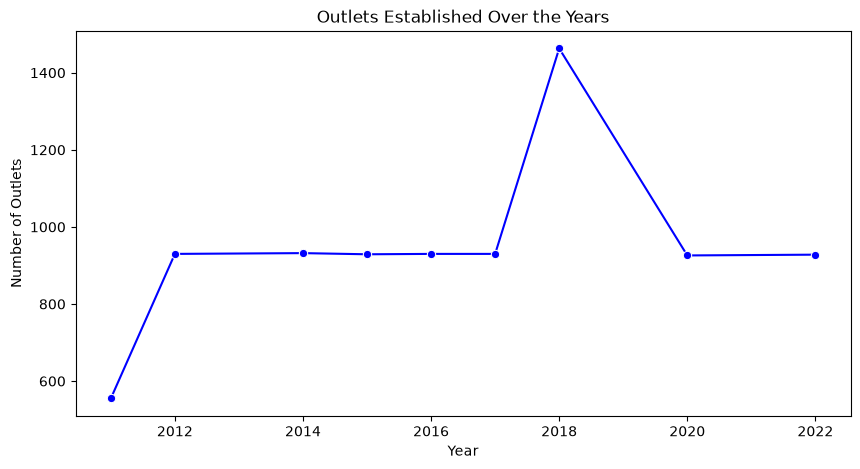

In [173]:
plt.figure(figsize=(10,5))
sns.lineplot(
    x=outlet_year.index,
    y=outlet_year.values,
    marker="o",
    color="blue"
)
plt.title("Outlets Established Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Outlets")
plt.show()
plt.close()

7.Which Item Fat Content generates the highest revenue?

In [174]:
fat_sales = df.groupby("Item Fat Content")["Sales"].sum()
fat_sales = fat_sales.sort_values(ascending=False)
print(fat_sales)

Item Fat Content
Low Fat    717390.8474
Regular    409413.1234
LF          43857.1082
reg         15948.6810
low fat     15071.7328
Name: Sales, dtype: float64


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_5464\930889024.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


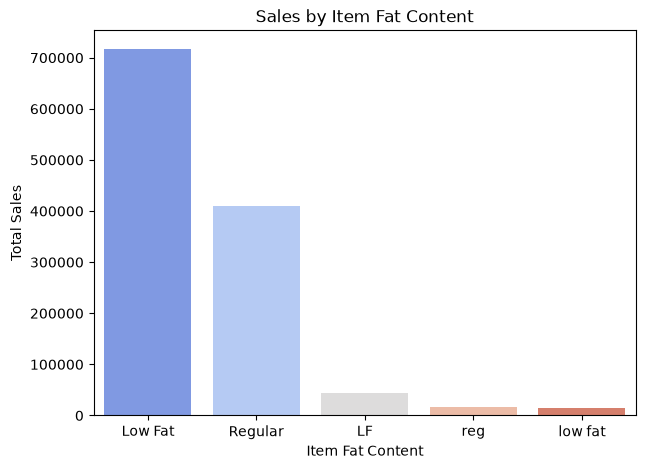

In [175]:
plt.figure(figsize=(7,5))
sns.barplot(
    x=fat_sales.index,
    y=fat_sales.values,
    palette="coolwarm"
)
plt.title("Sales by Item Fat Content")
plt.xlabel("Item Fat Content")
plt.ylabel("Total Sales")
plt.show()
plt.close()

8.Is there any relationship between Item Visibility and Sales?

In [176]:
visibility_sales = df[["Item Visibility", "Sales"]]
print(visibility_sales)

      Item Visibility     Sales
0            0.100014  145.4786
1            0.008596  115.3492
2            0.025896  165.0210
3            0.042278  126.5046
4            0.033970   55.1614
...               ...       ...
8518         0.000000  164.5526
8519         0.034706  241.6828
8520         0.027571   86.6198
8521         0.107715   97.8752
8522         0.000000  112.2544

[8523 rows x 2 columns]


In [177]:
correlation = visibility_sales.corr()
print(correlation)

                 Item Visibility     Sales
Item Visibility         1.000000 -0.001315
Sales                  -0.001315  1.000000


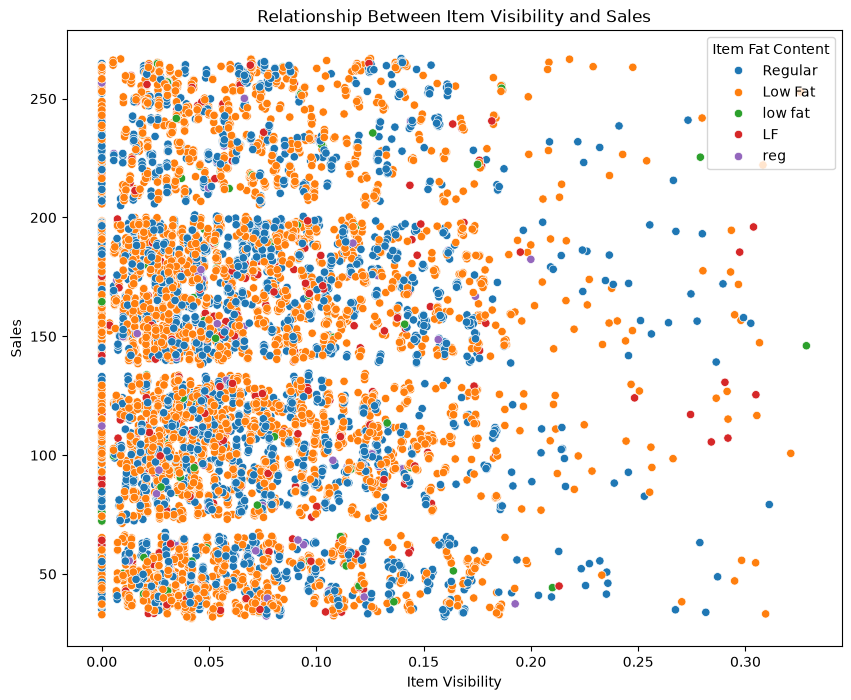

In [178]:
plt.figure(figsize=(10,8))
sns.scatterplot(
    data=df,
    x="Item Visibility",
    y="Sales",
    hue="Item Fat Content"
)
plt.title("Relationship Between Item Visibility and Sales")
plt.xlabel("Item Visibility")
plt.ylabel("Sales")
plt.show()
plt.close()

9. Which products have the highest average customer rating ?

In [179]:
rating = df.groupby("Item Type")["Rating"].mean()
rating = rating.sort_values(ascending=False)
print(rating)

Item Type
Meat                     4.023059
Household                3.998681
Canned                   3.994299
Health and Hygiene       3.986154
Baking Goods             3.983025
Frozen Foods             3.971145
Dairy                    3.965836
Seafood                  3.959375
Fruits and Vegetables    3.956169
Others                   3.954438
Snack Foods              3.948917
Breakfast                3.932727
Soft Drinks              3.920674
Starchy Foods            3.920270
Hard Drinks              3.907477
Breads                   3.881275
Name: Rating, dtype: float64


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_5464\1355948660.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


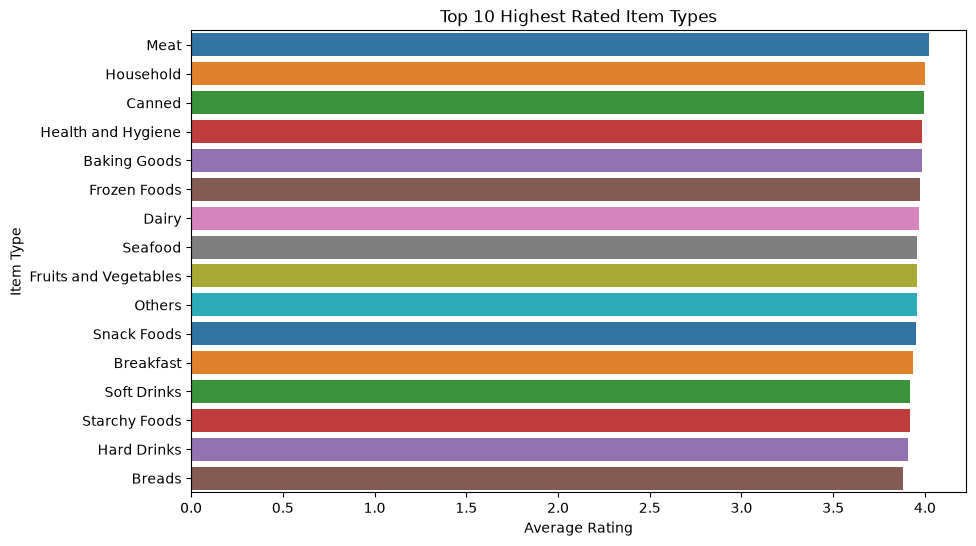

In [180]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=rating.values,
    y=rating.index,
    palette="tab10"
)
plt.title("Top 10 Highest Rated Item Types")
plt.xlabel("Average Rating")
plt.ylabel("Item Type")
plt.show()
plt.close()